# **04 · Visualización de resultados**

Genera las predicciones y los gráficos finales del proyecto:

1. Comparación del modelo base y el optimizado sobre las fotos de **test**.
2. Curvas de entrenamiento (convergencia).
3. Predicciones del modelo sobre fotos que no vio al entrenar.
4. Matriz de confusión.
5. Histogramas de errores.
6. Errores según las features del notebook 01.

Todas las figuras y tablas se guardan en `results/`.

> **Antes de empezar:** haber corrido los notebooks 01 y 02 (y el 03, para tener el modelo optimizado; si
> todavía no está, el notebook funciona igual solo con el modelo base). Con GPU es más rápido, pero no hace falta.

## **1. Preparación del entorno**

In [3]:
!pip -q install "ultralytics==8.4.153"

In [4]:
# Carpetas del proyecto. En Colab todo queda en Drive (carpeta limon_ia), con la misma estructura
# que el repositorio: data/, results/ y runs/ (modelos entrenados). Fuera de Colab se usa el repositorio.
from pathlib import Path

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/limon_ia")   # carpeta del proyecto en Drive
    TRABAJO = Path("/content")                        # disco de Colab: rápido, pero se borra al cerrar
except ImportError:
    BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    TRABAJO = BASE / "data"

DATA, RESULTS, RUNS = BASE / "data", BASE / "results", BASE / "runs"
for carpeta in (DATA, RESULTS, RUNS):
    carpeta.mkdir(parents=True, exist_ok=True)
DATOS = TRABAJO / "datos"                             # dataset unificado, descomprimido
print("Proyecto en", BASE)

Mounted at /content/drive
Proyecto en /content/drive/MyDrive/limon_ia


In [5]:
import shutil
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from ultralytics import YOLO

IMGSZ = 640        # tamaño de imagen, el mismo del entrenamiento
CONF_MIN = 0.40    # confianza mínima para aceptar una detección
IOU_MIN = 0.50     # superposición mínima con la caja real para contar una detección como acierto

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [6]:
# --------
# Función que deja listo el dataset para entrenar.
#   - Descomprime data/datos_limon.zip (lo genera el notebook 01) si todavía no está en el disco.
#   - Repite "repetir" veces las fotos propias de entrenamiento (sobremuestreo), para que pesen más
#     frente a las 915 imágenes del dataset base.
#   - Devuelve: la ruta del archivo .yaml que le dice a YOLO dónde están train y val.
# --------
def preparar_datos(repetir=3):
    if not (DATOS / "propio").exists():
        shutil.unpack_archive(DATA / "datos_limon.zip", DATOS)
    rep = DATOS / "propio" / f"train_x{repetir}"
    if not rep.exists():
        for sub in ("images", "labels"):
            (rep / sub).mkdir(parents=True)
        for img in sorted((DATOS / "propio" / "train" / "images").iterdir()):
            etiqueta = DATOS / "propio" / "train" / "labels" / (img.stem + ".txt")
            for k in range(repetir):
                shutil.copy(img, rep / "images" / f"r{k}_{img.name}")
                shutil.copy(etiqueta, rep / "labels" / f"r{k}_{img.stem}.txt")
    # train: todo el dataset base + las fotos propias de train repetidas. val: las 10 fotos propias de valid.
    train = [str(DATOS / "base" / s / "images") for s in ("train", "valid", "test")
             if any((DATOS / "base" / s / "images").glob("*"))] + [str(rep / "images")]
    ruta = TRABAJO / f"limones_x{repetir}.yaml"
    ruta.write_text(yaml.safe_dump({"train": train, "val": str(DATOS / "propio" / "valid" / "images"),
                                    "nc": 1, "names": {0: "limon"}}))
    return str(ruta)


# --------
# Función que evalúa un modelo sobre una o más carpetas de imágenes.
#   - Recibe: el modelo, un nombre para la fila y los conjuntos propios a usar ("valid", "test").
#   - Devuelve: diccionario con precisión, recobrado, F1, mAP50 y mAP50-95.
# --------
def evaluar(modelo, nombre, conjuntos):
    carpetas = [str(DATOS / "propio" / c / "images") for c in conjuntos]
    ruta = TRABAJO / f"eval_{'_'.join(conjuntos)}.yaml"
    ruta.write_text(yaml.safe_dump({"train": carpetas, "val": carpetas, "nc": 1, "names": {0: "limon"}}))
    m = modelo.val(data=str(ruta), imgsz=IMGSZ, project=str(TRABAJO / "evals"), name=nombre, exist_ok=True,
                   verbose=False, plots=False)
    p, r = float(m.box.mp), float(m.box.mr)
    return {"modelo": nombre, "conjunto": "+".join(conjuntos),
            "imágenes": sum(len(list(Path(c).glob("*"))) for c in carpetas),
            "precisión": round(p, 3), "recobrado": round(r, 3), "F1": round(2 * p * r / (p + r + 1e-9), 3),
            "mAP50": round(float(m.box.map50), 3), "mAP50-95": round(float(m.box.map), 3)}

In [7]:
preparar_datos()

# Cargamos los modelos entrenados que haya.
modelos = {nombre: YOLO(str(RUNS / nombre / "weights" / "best.pt"))
           for nombre in ("base", "optimizado") if (RUNS / nombre / "weights" / "best.pt").exists()}
print("Modelos disponibles:", list(modelos))

Modelos disponibles: ['base', 'optimizado']


## **2. Comparación de modelos en test**

- **test (10 fotos):** el modelo no las vio nunca, ni para entrenar ni para elegir hiperparámetros. Es la
  medida más honesta.
- **valid+test (20 fotos):** más limones, así que el número es más estable, pero las 10 de validación se
  usaron para elegir el mejor modelo y los hiperparámetros: es algo optimista.

In [8]:
filas = []
for nombre, modelo in modelos.items():
    filas.append(evaluar(modelo, nombre, ["test"]))
    filas.append(evaluar(modelo, nombre, ["valid", "test"]))
comparacion = pd.DataFrame(filas)
comparacion.to_csv(RESULTS / "comparacion_modelos.csv", index=False)

# Para el resto del notebook se usa el modelo con mejor mAP50-95 en validación (no en test, para no
# elegir el modelo con las mismas fotos con las que se lo evalúa).
en_valid = {nombre: evaluar(modelo, nombre, ["valid"])["mAP50-95"] for nombre, modelo in modelos.items()}
ELEGIDO = max(en_valid, key=en_valid.get)
modelo = modelos[ELEGIDO]
print("mAP50-95 en validación:", en_valid, "-> se analiza el modelo:", ELEGIDO)
comparacion

Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1488.9±569.1 MB/s, size: 80.6 KB)
val: Scanning /content/datos/propio/test/labels... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 215.9it/s 0.0s
val: New cache created: /content/datos/propio/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.6s/it 1.6s
                   all         10         58       0.96      0.862      0.938      0.723
Speed: 0.6ms preprocess, 9.5ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.153 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2124.3±816.7 MB/s, size: 78.4 KB)
val: Scanni

,modelo,conjunto,imágenes,precisión,recobrado,F1,mAP50,mAP50-95
0,base,test,10,0.960,0.862,0.908,0.938,0.723
1,base,valid+test,20,0.929,0.922,0.926,0.952,0.746
2,optimizado,test,10,0.963,0.948,0.956,0.967,0.729
3,optimizado,valid+test,20,0.956,0.966,0.961,0.983,0.762


## **3. Curvas de entrenamiento (convergencia)**

Arriba, las pérdidas: deben bajar. La de entrenamiento mide el error sobre las imágenes con las que se ajustan
los pesos; la de validación, sobre las 10 fotos propias que no se usan para ajustar. Si la de validación sube
mientras la de entrenamiento sigue bajando, hay sobreajuste. Abajo, las métricas en validación: deben subir y
estabilizarse. La línea punteada marca la mejor época (la que se guarda como `best.pt`).

base: 51 épocas entrenadas, mejor época: 31
optimizado: 60 épocas entrenadas, mejor época: 56


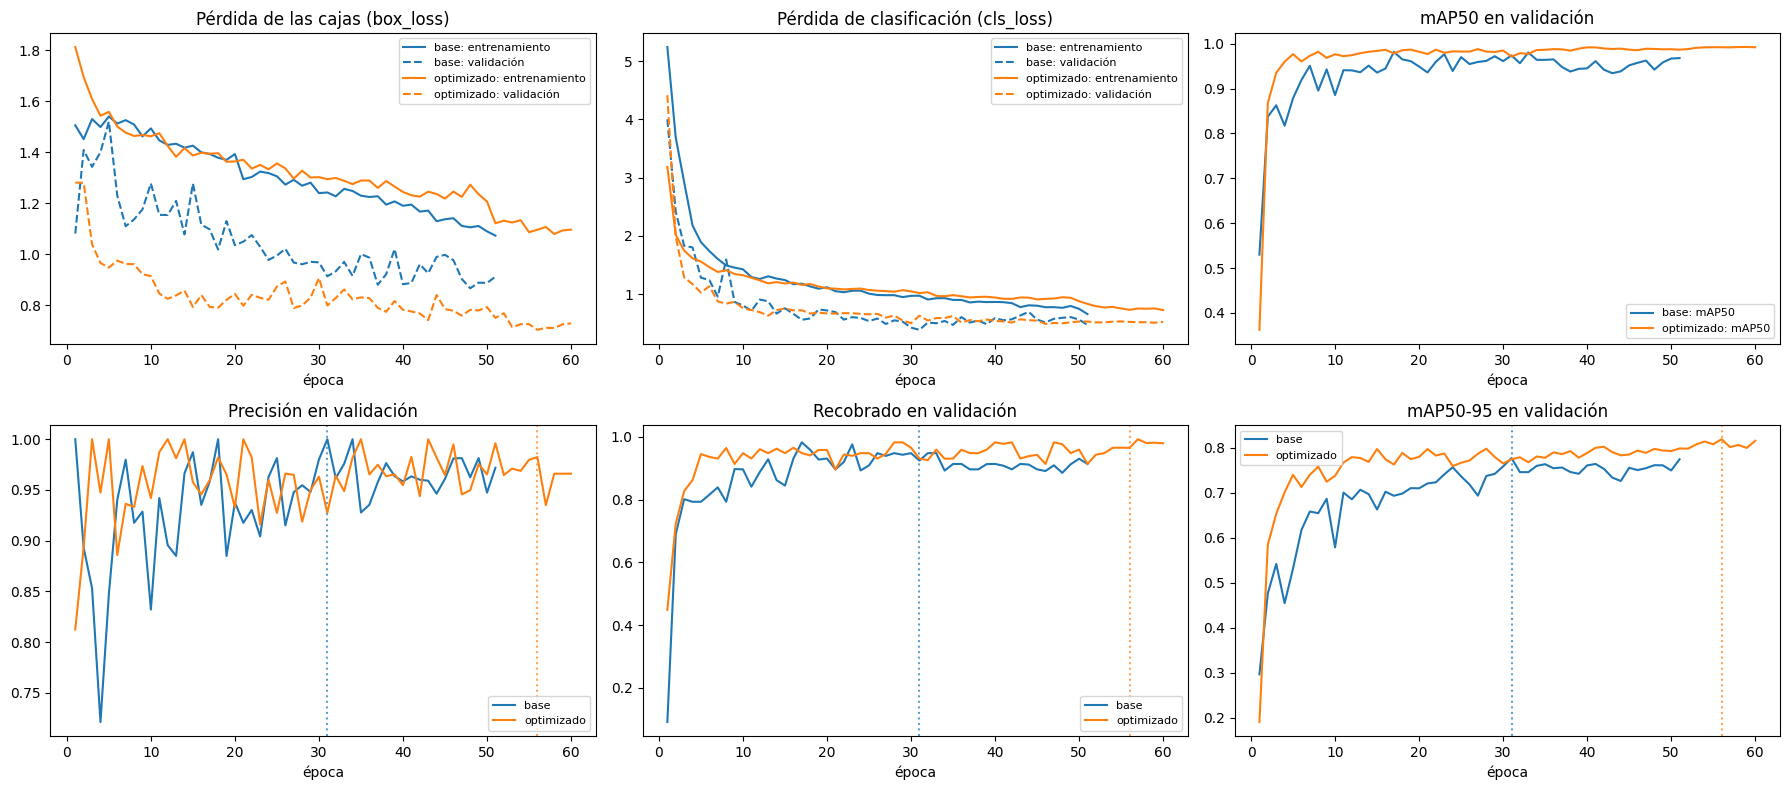

In [9]:
fig, ejes = plt.subplots(2, 3, figsize=(18, 8))
colores = {"base": "#1f77b4", "optimizado": "#ff7f0e"}
for nombre in modelos:
    c = pd.read_csv(RUNS / nombre / "results.csv")
    c.columns = c.columns.str.strip()
    mejor_epoca = int(c.loc[c["metrics/mAP50-95(B)"].idxmax(), "epoch"])
    for ax, perdida in zip(ejes[0], ("box_loss", "cls_loss")):
        ax.plot(c["epoch"], c[f"train/{perdida}"], color=colores[nombre], label=f"{nombre}: entrenamiento")
        ax.plot(c["epoch"], c[f"val/{perdida}"], color=colores[nombre], linestyle="--", label=f"{nombre}: validación")
        ax.set_title("Pérdida de las cajas (box_loss)" if perdida == "box_loss" else "Pérdida de clasificación (cls_loss)")
    ejes[0][2].plot(c["epoch"], c["metrics/mAP50(B)"], color=colores[nombre], label=f"{nombre}: mAP50")
    ejes[0][2].set_title("mAP50 en validación")
    for ax, (col, titulo) in zip(ejes[1], (("metrics/precision(B)", "Precisión en validación"),
                                           ("metrics/recall(B)", "Recobrado en validación"),
                                           ("metrics/mAP50-95(B)", "mAP50-95 en validación"))):
        ax.plot(c["epoch"], c[col], color=colores[nombre], label=nombre)
        ax.axvline(mejor_epoca, color=colores[nombre], linestyle=":", alpha=0.7)
        ax.set_title(titulo)
    print(f"{nombre}: {len(c)} épocas entrenadas, mejor época: {mejor_epoca}")
for ax in ejes.flat:
    ax.set_xlabel("época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "fig_curvas_entrenamiento.png", dpi=110)
plt.show()

## **4. Predicciones**

El modelo elegido predice sobre las 20 fotos propias que no se usaron para ajustar los pesos (valid + test).
Cada detección se compara con las etiquetas reales:

- **Acierto (VP):** la detección se superpone al menos 50 % (IoU ≥ 0,5) con un limón real todavía no asignado.
- **Falso positivo (FP):** una detección que no corresponde a ningún limón, o un limón marcado dos veces.
- **Falso negativo (FN):** un limón real que el modelo no detectó.

El **IoU** (*intersection over union*) es el área en común de dos cajas dividida por el área que cubren entre
las dos: 1 es superposición perfecta y 0, ninguna.

In [10]:
# --------
# Función que calcula el IoU entre una caja y varias, todas como (x1, y1, x2, y2).
# --------
def iou(caja, cajas):
    x1, y1 = np.maximum(caja[0], cajas[:, 0]), np.maximum(caja[1], cajas[:, 1])
    x2, y2 = np.minimum(caja[2], cajas[:, 2]), np.minimum(caja[3], cajas[:, 3])
    comun = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda c: (c[..., 2] - c[..., 0]) * (c[..., 3] - c[..., 1])
    return comun / (area(caja) + area(cajas) - comun + 1e-9)


# --------
# Función que lee las cajas reales de una imagen, en píxeles, como (x1, y1, x2, y2).
# --------
def cajas_reales(img, ancho, alto):
    filas = [l.split() for l in (img.parent.parent / "labels" / (img.stem + ".txt")).read_text().splitlines()
             if l.strip()]
    c = np.array([[float(v) for v in f[1:5]] for f in filas]).reshape(-1, 4)
    return np.stack([(c[:, 0] - c[:, 2] / 2) * ancho, (c[:, 1] - c[:, 3] / 2) * alto,
                     (c[:, 0] + c[:, 2] / 2) * ancho, (c[:, 1] + c[:, 3] / 2) * alto], axis=1)


fotos = [f for conj in ("valid", "test") for f in sorted((DATOS / "propio" / conj / "images").iterdir())]
detecciones, reales, resultados = [], [], {}
for foto in fotos:
    r = modelo.predict(str(foto), conf=CONF_MIN, imgsz=IMGSZ, verbose=False)[0]
    resultados[foto.name] = r
    alto, ancho = r.orig_shape
    gt = cajas_reales(foto, ancho, alto)
    pred, conf = r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()
    asignado = np.full(len(gt), -1)             # qué detección le tocó a cada limón real
    for i in np.argsort(-conf):                 # de la detección más confiable a la menos
        ious = iou(pred[i], gt) if len(gt) else np.array([])
        ious[asignado >= 0] = 0                 # un limón real solo puede asignarse una vez
        j = int(ious.argmax()) if len(ious) else -1
        acierto = j >= 0 and ious[j] >= IOU_MIN
        error_centro = np.nan
        if acierto:
            asignado[j] = i
            # Distancia entre el centro detectado y el real, como % del lado del limón.
            centro = lambda c: np.array([(c[0] + c[2]) / 2, (c[1] + c[3]) / 2])
            lado = ((gt[j][2] - gt[j][0]) * (gt[j][3] - gt[j][1])) ** 0.5
            error_centro = 100 * np.linalg.norm(centro(pred[i]) - centro(gt[j])) / lado
        detecciones.append({"imagen": foto.name, "conjunto": foto.parent.parent.name,
                            "confianza": round(float(conf[i]), 3), "resultado": "VP" if acierto else "FP",
                            "iou": round(float(ious[j]), 3) if j >= 0 else 0.0,
                            "error_centro_pct": round(float(error_centro), 2), "n": j if acierto else -1})
    for j in range(len(gt)):
        reales.append({"imagen": foto.name, "conjunto": foto.parent.parent.name, "n": j,
                       "detectado": bool(asignado[j] >= 0)})

detecciones = pd.DataFrame(detecciones, columns=["imagen", "conjunto", "confianza", "resultado", "iou",
                                                 "error_centro_pct", "n"])
reales = pd.DataFrame(reales)
detecciones.to_csv(RESULTS / "predicciones.csv", index=False)
VP, FP, FN = (detecciones["resultado"] == "VP").sum(), (detecciones["resultado"] == "FP").sum(), \
    (~reales["detectado"]).sum()
print(f"Modelo {ELEGIDO}, {len(fotos)} fotos, {len(reales)} limones reales (conf ≥ {CONF_MIN}, IoU ≥ {IOU_MIN})")
print(f"Aciertos (VP): {VP} | falsos positivos (FP): {FP} | falsos negativos (FN): {FN}")
print(f"Precisión = {VP / max(VP + FP, 1):.3f} | recobrado = {VP / max(VP + FN, 1):.3f}")
detecciones.head(10)

Modelo optimizado, 20 fotos, 116 limones reales (conf ≥ 0.4, IoU ≥ 0.5)
Aciertos (VP): 103 | falsos positivos (FP): 4 | falsos negativos (FN): 13
Precisión = 0.963 | recobrado = 0.888


,imagen,conjunto,confianza,resultado,iou,error_centro_pct,n
0,limon_008_jpg.rf.69da2b3fea4c26dbb061642232f77...,valid,0.955,VP,0.946,1.98,0
1,limon_008_jpg.rf.69da2b3fea4c26dbb061642232f77...,valid,0.949,VP,0.972,0.98,2
2,limon_008_jpg.rf.69da2b3fea4c26dbb061642232f77...,valid,0.916,VP,0.660,18.28,4
3,limon_008_jpg.rf.69da2b3fea4c26dbb061642232f77...,valid,0.905,VP,0.862,5.92,3
4,limon_008_jpg.rf.69da2b3fea4c26dbb061642232f77...,valid,0.874,VP,0.933,2.46,1
5,limon_010_jpg.rf.da42e01845e5875193046ec8a00ed...,valid,0.943,VP,0.912,3.79,0
6,limon_010_jpg.rf.da42e01845e5875193046ec8a00ed...,valid,0.929,VP,0.846,9.36,3
7,limon_010_jpg.rf.da42e01845e5875193046ec8a00ed...,valid,0.926,VP,0.976,0.68,2
8,limon_010_jpg.rf.da42e01845e5875193046ec8a00ed...,valid,0.866,VP,0.885,3.01,4
9,limon_010_jpg.rf.da42e01845e5875193046ec8a00ed...,valid,0.637,FP,0.000,NaN,-1


**Nota.** La precisión y el recobrado de esta celda están calculados con un umbral de confianza fijo (0,40),
el que usa el robot. Los de la tabla de la sección 2 los calcula Ultralytics en el umbral que maximiza F1, así
que pueden diferir un poco.

### **4.1 Ejemplos: etiquetas reales contra predicción**

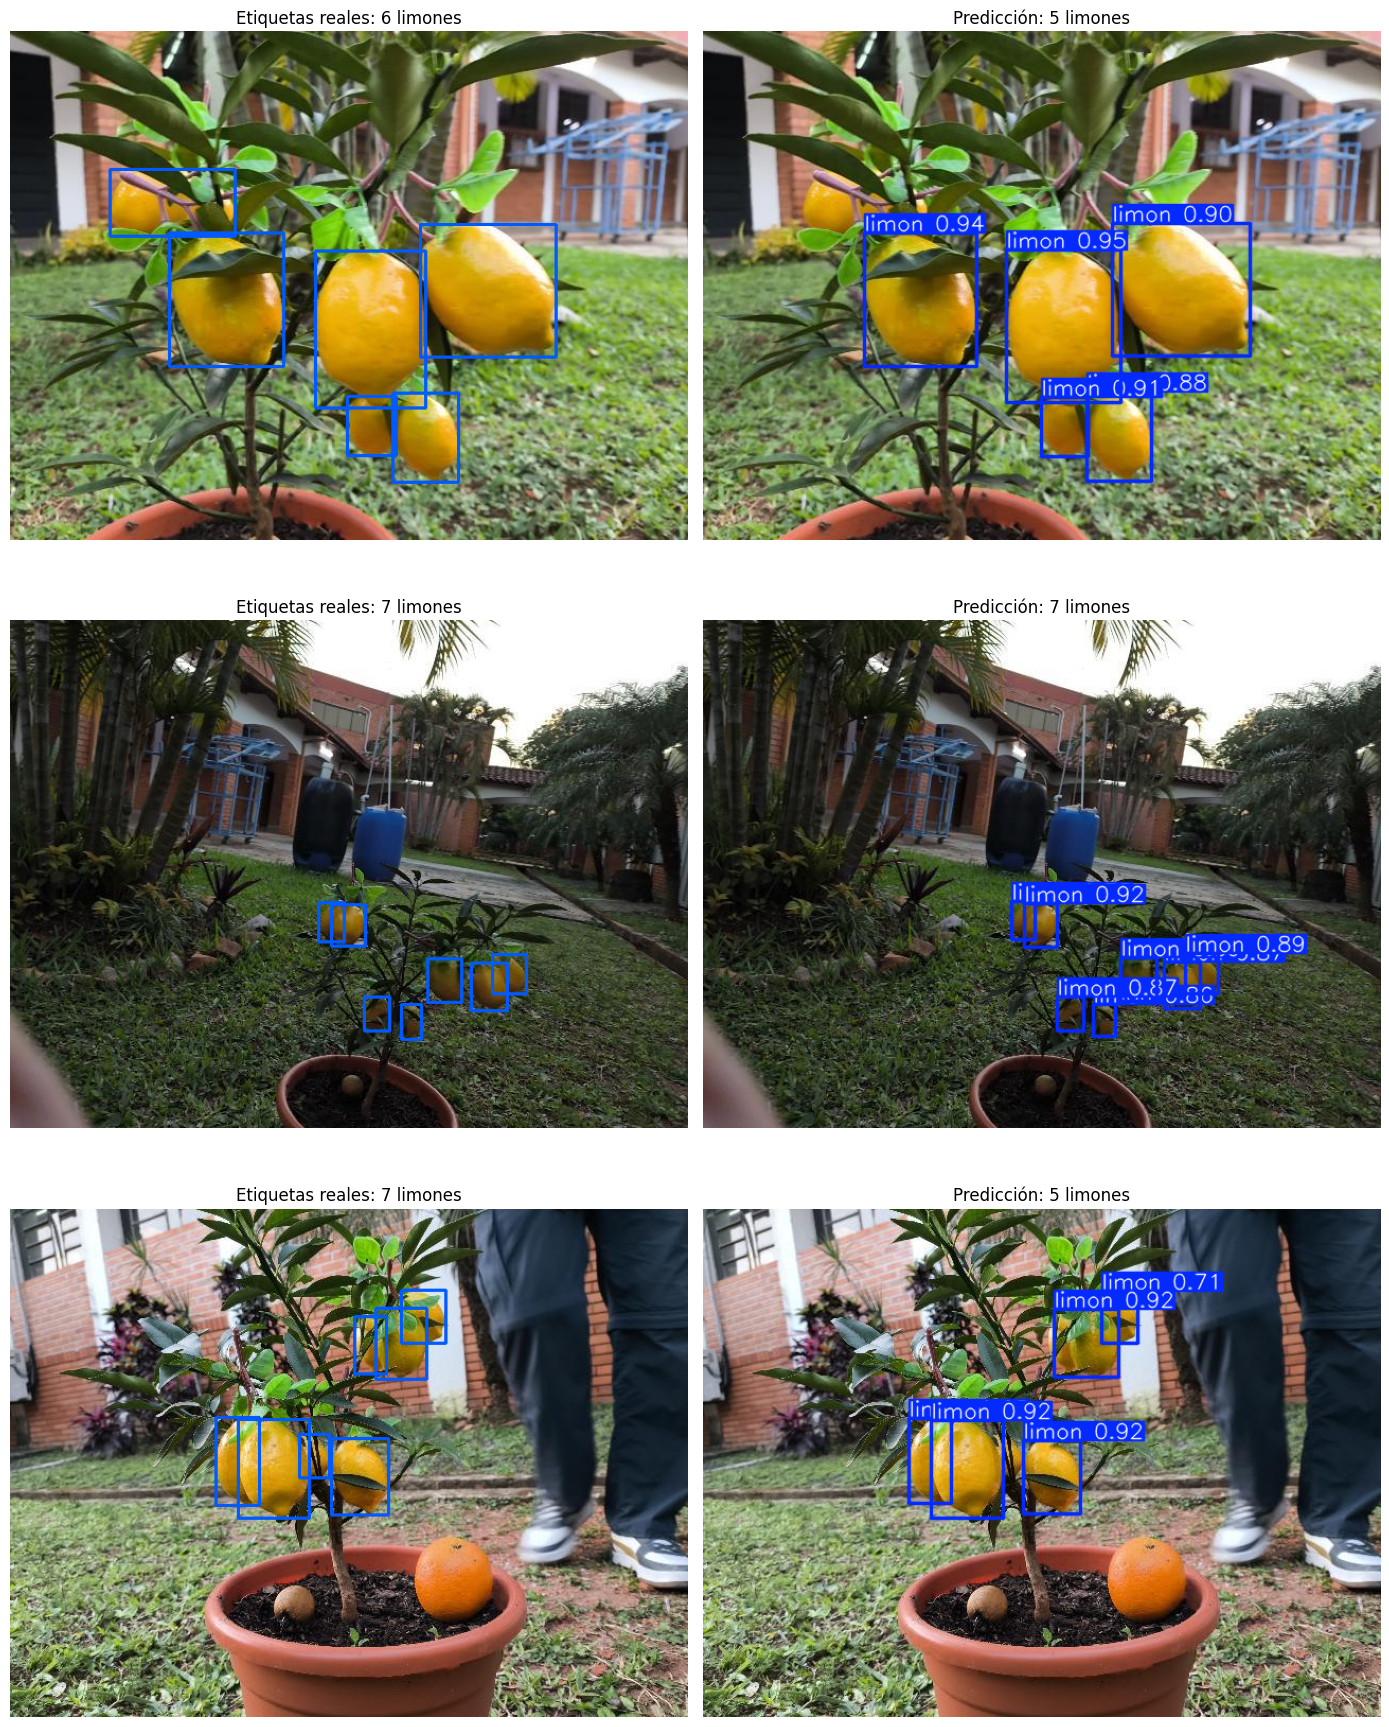

In [11]:
# --------
# Función que dibuja las cajas reales de una imagen.
# --------
def dibujar_reales(img):
    im = cv2.cvtColor(cv2.imread(str(img)), cv2.COLOR_BGR2RGB)
    for x1, y1, x2, y2 in cajas_reales(img, im.shape[1], im.shape[0]).astype(int):
        cv2.rectangle(im, (x1, y1), (x2, y2), (0, 90, 255), max(2, im.shape[1] // 300))
    return im


# Tres fotos de test al azar (cambiar la semilla para ver otras).
muestras = random.Random(0).sample(sorted((DATOS / "propio" / "test" / "images").iterdir()), 3)
plt.figure(figsize=(14, 18))
for i, foto in enumerate(muestras):
    r = resultados[foto.name]
    plt.subplot(3, 2, 2 * i + 1)
    plt.imshow(dibujar_reales(foto))
    plt.title(f"Etiquetas reales: {(reales['imagen'] == foto.name).sum()} limones")
    plt.axis("off")
    plt.subplot(3, 2, 2 * i + 2)
    plt.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    plt.title(f"Predicción: {len(r.boxes)} limones")
    plt.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "fig_predicciones.jpg", dpi=80)
plt.show()

## **5. Matriz de confusión**

Con una sola clase, la matriz tiene tres casilleros útiles: limones detectados (VP), limones que se escaparon
(FN) y detecciones de algo que no era un limón (FP). El cuarto ("fondo que se tomó por fondo") no se puede
contar en detección de objetos: no hay una cantidad definida de "no limones".

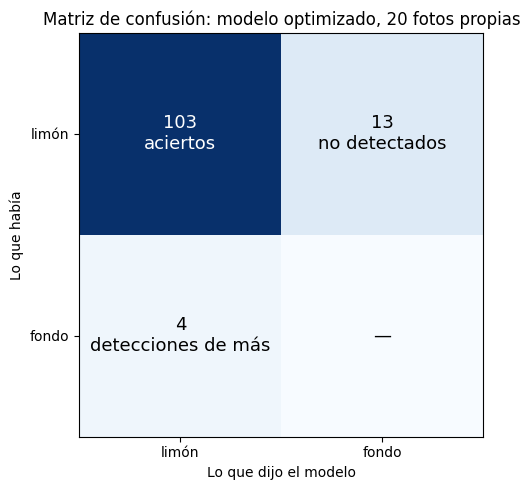

In [12]:
matriz = np.array([[VP, FN], [FP, 0]])
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(matriz, cmap="Blues")
ax.set_xticks([0, 1], ["limón", "fondo"]); ax.set_yticks([0, 1], ["limón", "fondo"])
ax.set_xlabel("Lo que dijo el modelo"); ax.set_ylabel("Lo que había")
textos = [[f"{VP}\naciertos", f"{FN}\nno detectados"], [f"{FP}\ndetecciones de más", "—"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, textos[i][j], ha="center", va="center", fontsize=13,
                color="white" if matriz[i, j] > matriz.max() / 2 else "black")
ax.set_title(f"Matriz de confusión: modelo {ELEGIDO}, {len(fotos)} fotos propias")
plt.tight_layout()
plt.savefig(RESULTS / "fig_matriz_confusion.png", dpi=110)
plt.show()

## **6. Histogramas de errores**

En detección el error no es un solo número, así que se miran cuatro:

1. **Superposición (IoU) de los aciertos:** qué tan ajustadas son las cajas. Cuanto más cerca de 1, mejor.
2. **Error del centro:** distancia entre el centro detectado y el real, como porcentaje del tamaño del limón.
   Es el error que más le importa al robot: el brazo va hacia el centro de la caja.
3. **Confianza de aciertos y de falsos positivos:** si los falsos positivos tienen confianza baja, subir
   `CONF_MIN` los elimina sin perder limones.
4. **Error de conteo por foto:** limones detectados menos limones reales.

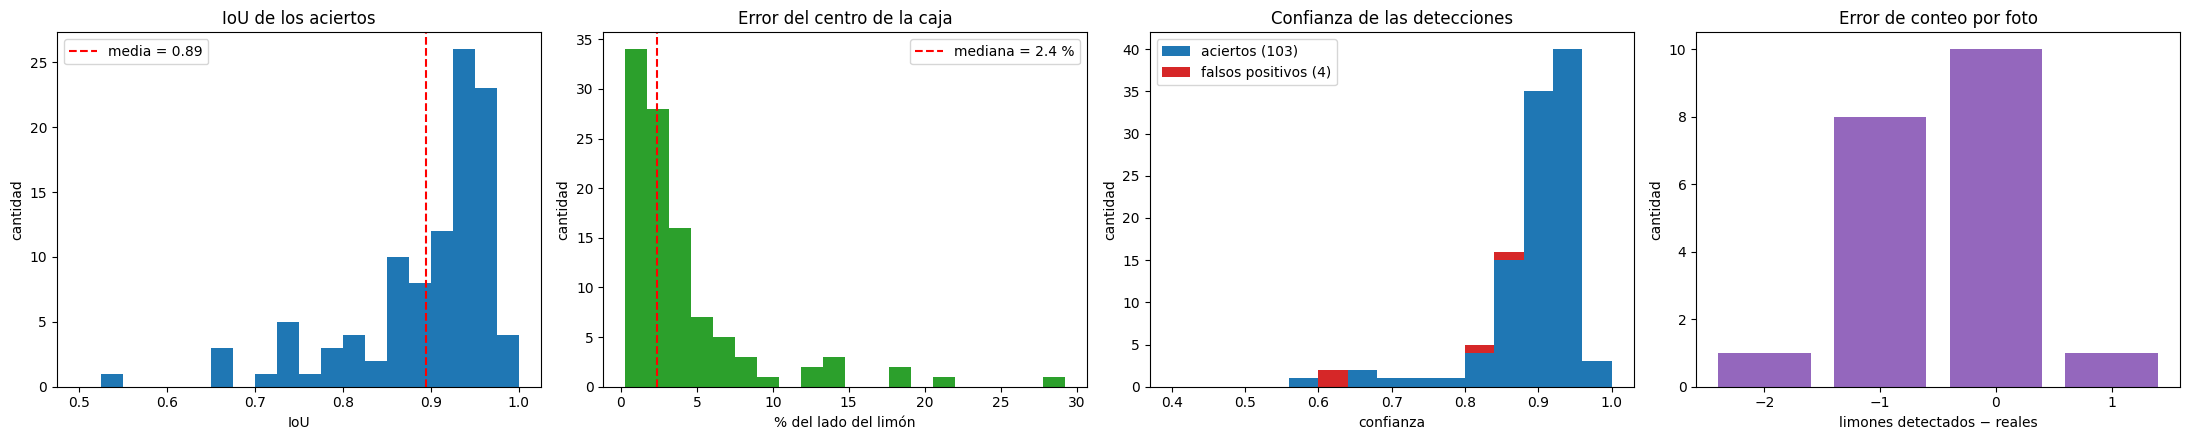

Fotos con el conteo exacto: 10 de 20


In [13]:
aciertos = detecciones[detecciones["resultado"] == "VP"]
falsos = detecciones[detecciones["resultado"] == "FP"]
conteo = (detecciones.groupby("imagen").size().reindex([f.name for f in fotos], fill_value=0)
          - reales.groupby("imagen").size().reindex([f.name for f in fotos], fill_value=0))

fig, ejes = plt.subplots(1, 4, figsize=(22, 4.5))
ejes[0].hist(aciertos["iou"], bins=np.linspace(IOU_MIN, 1, 21), color="#1f77b4")
ejes[0].axvline(aciertos["iou"].mean(), color="red", linestyle="--", label=f"media = {aciertos['iou'].mean():.2f}")
ejes[0].set_title("IoU de los aciertos"); ejes[0].set_xlabel("IoU"); ejes[0].legend()

ejes[1].hist(aciertos["error_centro_pct"], bins=20, color="#2ca02c")
ejes[1].axvline(aciertos["error_centro_pct"].median(), color="red", linestyle="--",
                label=f"mediana = {aciertos['error_centro_pct'].median():.1f} %")
ejes[1].set_title("Error del centro de la caja"); ejes[1].set_xlabel("% del lado del limón"); ejes[1].legend()

bins = np.linspace(CONF_MIN, 1, 16)
ejes[2].hist([aciertos["confianza"], falsos["confianza"]], bins=bins, stacked=True,
             color=["#1f77b4", "#d62728"], label=[f"aciertos ({len(aciertos)})", f"falsos positivos ({len(falsos)})"])
ejes[2].set_title("Confianza de las detecciones"); ejes[2].set_xlabel("confianza"); ejes[2].legend()

valores = np.arange(conteo.min(), conteo.max() + 1)
ejes[3].bar(valores, [(conteo == v).sum() for v in valores], color="#9467bd")
ejes[3].set_xticks(valores)
ejes[3].set_title("Error de conteo por foto"); ejes[3].set_xlabel("limones detectados − reales")
for ax in ejes:
    ax.set_ylabel("cantidad")
plt.tight_layout()
plt.savefig(RESULTS / "fig_histogramas_error.png", dpi=110)
plt.show()
print(f"Fotos con el conteo exacto: {(conteo == 0).sum()} de {len(fotos)}")

## **7. Errores según las features**

Se cruzan los limones reales con las features del notebook 01 para ver **en qué tipo de limón se equivoca**
el modelo: recobrado según el tamaño, el brillo y la cantidad de limones en la foto. Con pocos limones por
grupo, los porcentajes son orientativos: el número sobre cada barra es la cantidad de limones del grupo.

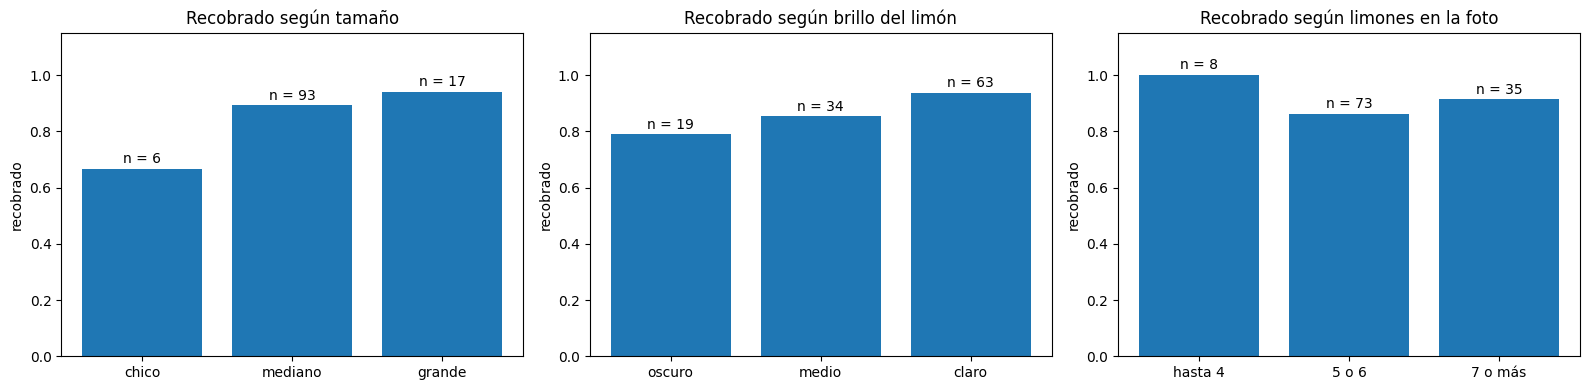

,feature,grupo,limones,recobrado
0,tamaño,chico,6,0.667
1,tamaño,mediano,93,0.892
2,tamaño,grande,17,0.941
0,brillo del limón,oscuro,19,0.789
1,brillo del limón,medio,34,0.853
2,brillo del limón,claro,63,0.937
0,limones en la foto,hasta 4,8,1.000
1,limones en la foto,5 o 6,73,0.863
2,limones en la foto,7 o más,35,0.914


In [14]:
features = pd.read_csv(RESULTS / "features_limones.csv")
cruce = reales.merge(features[features["dataset"] == "propio"], on=["imagen", "conjunto", "n"], how="left")
cruce["tamaño"] = pd.Categorical(cruce["tamano"], ["chico", "mediano", "grande"])
cruce["brillo del limón"] = pd.cut(cruce["brillo"], [0, 0.5, 0.75, 1.01], labels=["oscuro", "medio", "claro"])
cruce["limones en la foto"] = pd.cut(cruce["n_limones"], [0, 4, 6, 100], labels=["hasta 4", "5 o 6", "7 o más"])

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
tablas = []
for ax, col in zip(ejes, ("tamaño", "brillo del limón", "limones en la foto")):
    g = cruce.groupby(col, observed=True)["detectado"].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color="#1f77b4")
    for x, (media, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(x, media + 0.02, f"n = {n}", ha="center")
    ax.set_ylim(0, 1.15); ax.set_ylabel("recobrado"); ax.set_title(f"Recobrado según {col}")
    tablas.append(g.rename(columns={"mean": "recobrado", "size": "limones"}).assign(feature=col).reset_index(names="grupo"))
plt.tight_layout()
plt.savefig(RESULTS / "fig_recobrado_por_feature.png", dpi=110)
plt.show()
por_feature = pd.concat(tablas)[["feature", "grupo", "limones", "recobrado"]].round(3)
por_feature.to_csv(RESULTS / "recobrado_por_feature.csv", index=False)
por_feature

## **8. Conclusiones**

- **Modelo final:** el **optimizado**. En las 10 fotos de test (que no se usaron para elegir nada) dio P = 0,963, R = 0,948, F1 = 0,956, mAP50 = 0,967 y mAP50-95 = 0,729; el base dio P = 0,960, R = 0,862 y mAP50-95 = 0,723. La ganancia está sobre todo en el recobrado (+0,086); en mAP50-95 es de apenas +0,006, que con 58 limones no es una diferencia que se pueda sostener.
- **Criterio P y R ≥ 0,80:** se cumple en test y en validación + test (P = 0,956, R = 0,966), con los dos modelos.
- **Convergencia:** el modelo optimizado entrenó las 60 épocas (mejor: la 56), con la pérdida de validación bajando hasta el final (0,91 a 0,73) y sin señal clara de sobreajuste. El base paró en la época 51 (mejor: la 31).
- **Errores:** sobre las 20 fotos (116 limones, confianza ≥ 0,40 e IoU ≥ 0,5) hay 103 aciertos, 4 falsos positivos y 13 limones que se escapan. Con ese umbral fijo el recobrado es 0,888, menor que el 0,966 de la tabla de métricas, que se calcula con el umbral de confianza que maximiza F1; conviene tenerlo presente al usar el modelo en el robot. Los falsos positivos son pocos (4) y de confianza media (alrededor de 0,6 a 0,85). El modelo tiende a contar de menos (8 fotos con 1 limón menos). Según la sección 7, falla más con limones **chicos** (recobrado 0,67 con solo 6 casos), **oscuros** (0,79) y en fotos de 5 o 6 limones (0,86). En los limones claros y grandes acierta 0,94.
- **Limitaciones:** el test tiene 10 fotos del mismo árbol y del mismo día que las de entrenamiento, así que las métricas son optimistas y varían mucho; los cortes por tamaño o brillo tienen pocos casos. Las fotos son de celular y el robot usa otras cámaras. El dataset público parece incluir imágenes ilustradas o generadas, que se usaron solo para entrenar. El detector está pensado para un ambiente controlado (limonero en maceta, limones amarillos).